<!-- reader-content -->

# Spectra and parameter sweeps

<!-- notebook-download -->

Track an avoided crossing, inspect its dressed-state assignments, and change
the model's parameters without changing the defined chip.

quchip uses GHz for frequencies and couplings.

## Define the coupled model

Sweep one transmon through the other, where their bus-mediated interaction
produces an avoided crossing. For this study, use `RWA()` in a rotating
frame.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from quchip import RWA, Capacitive, ChargeDrive, Chip, DuffingTransmon, Resonator, SpectrumSweep, Sweep

q1_frequency = 5.30
q2_frequency0 = 5.58
bus_frequency = 6.55
q2_frequencies = np.linspace(5.255, 5.345, 181)
coupling_strength = 0.050

q1 = DuffingTransmon(
    freq=q1_frequency,
    anharmonicity=-0.65,
    levels=4,
    label="q1",
)
q2 = DuffingTransmon(
    freq=q2_frequency0,
    anharmonicity=-0.65,
    levels=4,
    label="q2",
)
bus = Resonator(freq=bus_frequency, levels=4, label="bus")

chip = Chip(
    [q1, q2, bus],
    couplings=[
        Capacitive(q1, bus, g=coupling_strength, label="q1-bus"),
        Capacitive(q2, bus, g=coupling_strength, label="q2-bus"),
    ],
    frame="rotating",
    approximation=RWA(),
)

## Sweep the avoided crossing

`Sweep` names the public parameter path to change, and `SpectrumSweep`
builds an isolated chip at each point, so the chip as you defined it does not
change. `overlap_threshold=0.0` keeps both intentionally hybridized
one-excitation labels available at the centre of the avoided crossing.

In [2]:
frequency_axis = Sweep(q2_frequencies, name="q2.freq")
sweep_result = SpectrumSweep(
    chip,
    [frequency_axis],
    evals_count=4,
    overlap_threshold=0.0,
).run(progress=False)

Subtract the ground energy from the two qubit-like branches. The
bus-like excitation stays above this frequency window.

In [3]:
ground_energy = sweep_result.eigenvalues[:, 0]
qubit_branches = sweep_result.eigenvalues[:, 1:3] - ground_energy[:, None]
lower_branch = qubit_branches[:, 0]
upper_branch = qubit_branches[:, 1]
splitting = upper_branch - lower_branch
q1_branch = sweep_result.dressed_index(q1=1, q2=0, bus=0).astype(int) - 1

minimum_index = int(np.argmin(splitting))
minimum_splitting = float(splitting[minimum_index])
minimum_frequency = float(q2_frequencies[minimum_index])
inferred_exchange_rate = 0.5 * minimum_splitting

q1_assignment = sweep_result.dressed_index(q1=1, q2=0, bus=0)
q1_label = (1, 0, 0)
q1_label_position = sweep_result.bare_labels.index(q1_label)
q1_assignment_overlap = np.asarray(
    sweep_result.assignment_overlaps[..., q1_label_position]
)

<details>
<summary>Plotting code</summary>

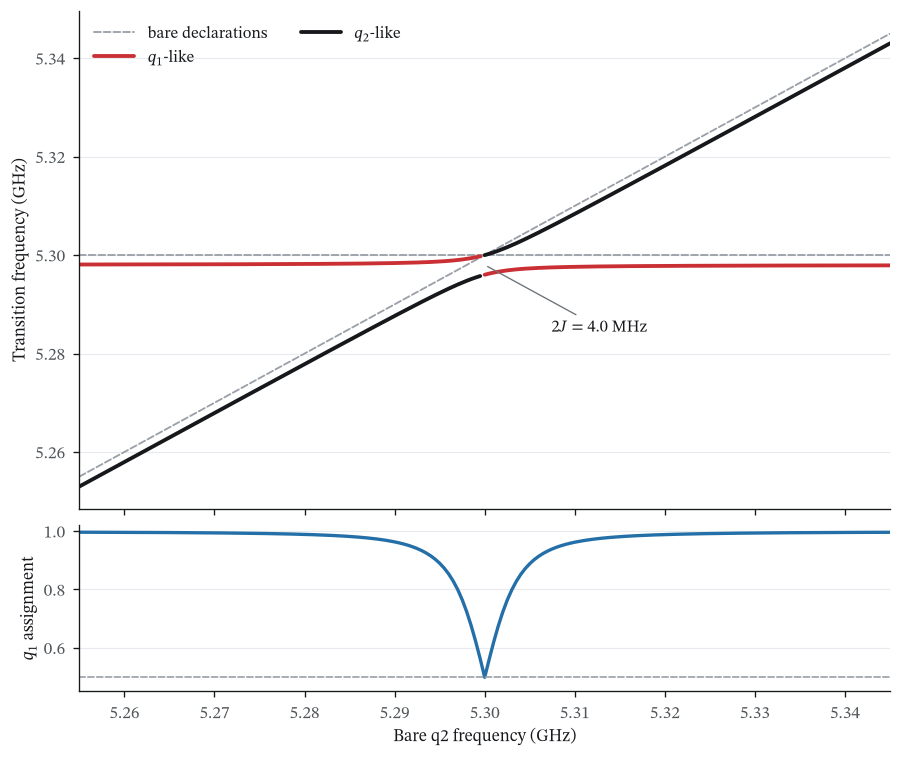

In [4]:
import shutil
from pathlib import Path

# In a quchip checkout, use the documentation style and save the figures there.
docs = Path("../docs")
if docs.is_dir():
    plt.style.use(docs / "_static/quchip.mplstyle")
plt.rcParams["text.usetex"] = bool(shutil.which("latex"))

figure, (axis, overlap_axis) = plt.subplots(
    2,
    1,
    figsize=(7.4, 6.2),
    height_ratios=(3.0, 1.0),
    sharex=True,
    layout="constrained",
)

axis.plot(q2_frequencies, q2_frequencies, color="#9AA0A8", linestyle="--", linewidth=1.1)
axis.axhline(q1_frequency, color="#9AA0A8", linestyle="--", linewidth=1.1, label="bare declarations")
for branch_index in (0, 1):
    q1_like = q1_branch == branch_index
    axis.plot(
        q2_frequencies,
        np.where(q1_like, qubit_branches[:, branch_index], np.nan),
        color="#C92F33",
        linewidth=2.3,
        label="$q_1$-like" if branch_index == 0 else None,
    )
    axis.plot(
        q2_frequencies,
        np.where(~q1_like, qubit_branches[:, branch_index], np.nan),
        color="#16181C",
        linewidth=2.3,
        label="$q_2$-like" if branch_index == 0 else None,
    )
axis.annotate(
    f"$2J$ = {1.0e3 * minimum_splitting:.1f} MHz",
    xy=(minimum_frequency, 0.5 * (lower_branch[minimum_index] + upper_branch[minimum_index])),
    xytext=(40, -40),
    textcoords="offset points",
    arrowprops={"arrowstyle": "-", "color": "#6D7277", "linewidth": 0.8},
    fontsize=10,
)
axis.set(
    ylabel="Transition frequency (GHz)",
    xlim=(q2_frequencies[0], q2_frequencies[-1]),
)
axis.legend(frameon=False, ncols=2, loc="upper left")

overlap_axis.plot(
    q2_frequencies,
    q1_assignment_overlap,
    color="#246FA8",
    linewidth=2.0,
)
overlap_axis.axhline(0.5, color="#9AA0A8", linestyle="--", linewidth=1.0)
overlap_axis.set(
    xlabel="Bare q2 frequency (GHz)",
    ylabel=r"$q_1$ assignment",
    ylim=(0.45, 1.02),
)

if docs.is_dir():
    figure.savefig(docs / "images/resolve_and_sweep.svg")
plt.show()

</details>

```{figure} ../images/resolve_and_sweep.svg
:width: 720px
:alt: Dressed transmon avoided crossing with the q1 bare-state assignment weight below

The bare frequencies cross while the dressed transitions retain a finite
splitting. The assignment weight exposes the hybridized region directly.
```

The dashed lines are the bare frequencies. Red follows the
more $q_1$-like dressed transition, and black the more $q_2$-like one. At the
crossing, the branch separation is $2J\approx4.0$ MHz. Second-order
dispersive perturbation theory gives $4.0$ MHz, and the two agree to 0.3%. The
RWA drops the counter-rotating coupling bands, and with `Exact()` their
Bloch–Siegert shift raises the splitting to approximately 4.4 MHz.

The lower panel shows why a bare-state label needs care at the crossing: its
assignment weight decreases to approximately one half as the two excitations
hybridize.

## Inspect the model after the sweep

The defined frequencies are inputs. `chip.freq()` returns dressed
$0\rightarrow1$ transitions, and `chip.static_zz()` returns the
conditional two-qubit shift for this coupled model.

In [5]:
q1_line = ChargeDrive(q1, label="q1-charge")
_ = chip.wire(q1_line)

static_zz = float(chip.static_zz(q1, q2))
kerr = chip.kerr_matrix()
element = complex(chip.drive_matrix_elements(q1, drives=[q1_line])[q1_line])

assert np.isclose(kerr[q1, q1], chip.dressed_anharmonicity(q1))
assert np.isclose(kerr[q1, bus], chip.dispersive_shift(q1, bus))

print(f"q1: f01 = {float(chip.freq(q1)):.6f} GHz, f12 = {float(chip.transition_frequency(q1, 1, 2)):.6f} GHz")
print(f"Static ZZ of q1 and q2: {1e6 * static_zz:.2f} kHz")
print(f"Drive matrix element <1|Q|0> of q1-charge: {element:.4f}")
print(f"Kerr matrix in MHz, rows and columns {kerr.labels}:")
print(np.array2string(1e3 * np.asarray(kerr.values), precision=4, floatmode="fixed"))

q1: f01 = 5.297989 GHz, f12 = 4.649377 GHz
Static ZZ of q1 and q2: 17.11 kHz
Drive matrix element <1|Q|0> of q1-charge: 0.0000+0.9992j
Kerr matrix in MHz, rows and columns ('q1', 'q2', 'bus'):
[[-6.4861e+02  1.7106e-02 -1.3540e+00]
 [ 1.7106e-02 -6.4800e+02 -2.0435e+00]
 [-1.3540e+00 -2.0435e+00 -4.6380e-03]]


`kerr_matrix()` puts the dressed anharmonicities on its diagonal and the
full-pull cross-Kerr shifts off the diagonal, in `chip.devices` order. The
two assertions above check its entries against the scalar APIs.

The resolved Hamiltonian, `chip.hamiltonian()`, applies the chip's basis,
frame, and approximation through the same path that simulation uses.
`chip.resolve().dropped_terms_summary()` lists the terms that the RWA
removed:

In [6]:
rwa_summary = chip.resolve().dropped_terms_summary()
print(rwa_summary)

4 term(s) dropped:
  [q1-bus] coupling band (-1, -1) on q1·bus  (discarded by RWA band selection; amp 0.15 GHz, detuning 10.55 GHz)
  [q1-bus] coupling band (+1, +1) on q1·bus  (discarded by RWA band selection; amp 0.15 GHz, detuning 10.55 GHz)
  [q2-bus] coupling band (-1, -1) on q2·bus  (discarded by RWA band selection; amp 0.15 GHz, detuning 10.83 GHz)
  [q2-bus] coupling band (+1, +1) on q2·bus  (discarded by RWA band selection; amp 0.15 GHz, detuning 10.83 GHz)


<details>
<summary>Numerical checks</summary>

In [7]:
second_order_splitting_scale = 2.0 * coupling_strength**2 / abs(bus_frequency - q1_frequency)
relative_difference_to_second_order = (
    abs(minimum_splitting - second_order_splitting_scale) / minimum_splitting
)

assert 0 < minimum_index < len(q2_frequencies) - 1, "the minimum lies at the sweep boundary"
assert len(chip.resolve().dropped_terms) == 4
assert chip.parameters["q2.freq"] == q2_frequency0, "SpectrumSweep changed the original chip"

print(f"Minimum splitting: {1e3 * minimum_splitting:.4f} MHz at bare q2 = {minimum_frequency:.3f} GHz")
print(f"Second-order estimate: {1e3 * second_order_splitting_scale:.4f} MHz, "
      f"{relative_difference_to_second_order:.1%} from the splitting")

Minimum splitting: 3.9873 MHz at bare q2 = 5.300 GHz
Second-order estimate: 4.0000 MHz, 0.3% from the splitting


</details>

## Change one design parameter

`with_params()` changes one bare frequency and keeps the source chip unchanged.

In [8]:
shifted_chip = chip.with_params({"q2.freq": 5.40})

print(f"Bare q2: {chip.parameters['q2.freq']} GHz in chip, {shifted_chip.parameters['q2.freq']} GHz in shifted_chip")
print(f"Dressed q2 of shifted_chip: {float(shifted_chip.freq('q2')):.6f} GHz")

Bare q2: 5.58 GHz in chip, 5.4 GHz in shifted_chip
Dressed q2 of shifted_chip: 5.397877 GHz


## Independent and linked parameter studies

`Sweep.expand()` shows the parameter dictionaries before a calculation starts.
Independent axes form a Cartesian grid, and `Sweep.zip()` pairs the values
of parameters that must move together.

In [9]:
frequency_values = Sweep([5.28, 5.30, 5.32], name="q2.freq")
coupling_values = Sweep([0.045, 0.050], name="q1-bus.g")
independent_points = Sweep.expand([frequency_values, coupling_values])

linked_points = Sweep.expand(
    [
        Sweep.zip(
            Sweep([5.28, 5.30, 5.32], name="q2.freq"),
            Sweep([0.045, 0.050, 0.055], name="q1-bus.g"),
        )
    ]
)

def show(point):
    return ", ".join(f"{name} = {float(value)}" for name, value in point.items())


print(f"{len(independent_points)} independent points, the first: {show(independent_points[0])}")
print(f"{len(linked_points)} linked points, the last: {show(linked_points[-1])}")

6 independent points, the first: q2.freq = 5.28, q1-bus.g = 0.045
3 linked points, the last: q2.freq = 5.32, q1-bus.g = 0.055


If each point needs a dressed spectrum, pass one of the two axis lists to
`SpectrumSweep`, and if you need only a few points or a custom observable,
use `with_params()` directly.

## Check labels before interpreting branches

Near an avoided crossing, several bare product states can share a dressed eigenstate.
`dressed_index()` tracks the assigned branch across the sweep, and `assignment_overlaps`
records the squared overlap with the assigned bare state. For one chip, `state_components()`
shows the largest bare-basis weights.

In [10]:
q1_components = chip.state_components({q1: 1}, n_components=3)

print(f"Tracked grid shape: {q1_assignment.shape}")
print(f"Lowest q1 assignment overlap: {float(np.nanmin(q1_assignment_overlap)):.4f}")
print("Bare components of the q1-like state:")
for label, weight in q1_components.items():
    print(f"  {label}: {weight:.3e}")

Tracked grid shape: (181,)
Lowest q1 assignment overlap: 0.4984
Bare components of the q1-like state:
  (1, 0, 0): 9.983e-01
  (0, 0, 1): 1.615e-03
  (0, 1, 0): 5.077e-05


At the crossing, each dressed branch contains approximately equal bare qubit
weights. A lower `overlap_threshold` keeps these labels but does not improve
their physical assignment.

## Check numerical resolution

The sweep grid resolves the minimum, while device `levels` control the
Hilbert-space truncation, and these are separate convergence questions. Here
the 181-point grid and its every-second-point subset agree, because both
contain the symmetry point.

In [11]:
fine_minimum = float(np.min(splitting))
coarse_minimum = float(np.min(splitting[::2]))

print(f"Minimum on {len(splitting)} points minus minimum on {len(splitting[::2])} points: "
      f"{1.0e9 * abs(fine_minimum - coarse_minimum):.1f} Hz")

Minimum on 181 points minus minimum on 91 points: 0.0 Hz


Check the local-level convergence separately for the reported transition,
matrix element, or dispersive shift.